# Real-data test of the final models

This notebook applies the final attention MLP, and the CNN for comparison, to three real phylogenies (Results on real data in the report). All outputs, tables and figures below are from the final run.

1. The simulated 3-interval, 500-tip trees are read and split exactly as in `main.ipynb` (same data, split, scaling of the eight values and training settings). The models are trained once with three seeds, or loaded from saved weights (`RETRAIN = False`).
2. The real trees (Zurich HIV, Nextstrain influenza H3N2, Nextstrain SARS-CoV-2) are turned into **500-tip trees** that look like the training trees (Section 5) and predicted with both models (Sections 7 and 8).
3. Section 10 checks the tree processing: a small tree worked out by hand, the large real trees (tips, times and groups of tips kept; files for a visual check in iTOL), and the conversion back to real units and to reproduction numbers.

**Models.** Both read the event list of a tree (7 numbers per event). The MLP has two masked self-attention blocks, the CNN three convolution layers. Both predict 8 values (λ₁, μ₁, λ₂, μ₂, λ₃, μ₃ and two change times), use log-scaled and standardised targets, the MAE loss, Adam 5e-4, batch 32, early stopping after 20 epochs, the 80/10/10 split with seed 42, and the average of three seeds on the log scale. The models accept event lists of any length (`Input(shape=(None, 7))`), so real trees with more events than the longest simulated tree can be predicted; the weights are unchanged by this.

**Why the models are trained here.** `main.ipynb` does not save its weights, so the final MLP and the CNN were retrained here with identical code and settings (overall error score 0.146 against 0.1466 in `main.ipynb`, within the variation between seeds). The real-data predictions use these retrained models, whose weights are in `m4_models.zip`.

**Saved weights.** The trained weights of every seed are saved (to Google Drive when `USE_DRIVE = True`) and packed in `m4_models.zip` at the end. The zip is also shared on Google Drive; its link is already set in `WEIGHTS_LINK` (the cell after the settings), so with `RETRAIN = False` the weights are downloaded and reused without training.

**How to run.**
1. Use a GPU runtime and upload the two simulation zips (`3-Interval-ChangeTime-free-10000-500tips-seed70-kept.zip`, `3-Interval-ChangeTime-different-10000-500tips-seed70-kept.zip`) to `/content`.
2. The influenza tree is not shared, because it is built from sequences shared via GISAID: open https://nextstrain.org/seasonal-flu/h3n2/ha/2y, choose "Download data" → "Newick (timetree)", and upload the file to `/content` as `nextstrain_seasonal-flu_h3n2_ha_2y_timetree.nwk`. Nextstrain updates this tree regularly, so a newer download gives slightly different influenza results. To repeat the influenza results in this notebook, use the same file as the original run.
3. Keep `RETRAIN = False` and Run all. The cells after the settings download the saved weights and the Zurich HIV and SARS-CoV-2 trees from Google Drive. With `USE_DRIVE = True`, Colab asks for access to your Google Drive and saves the weights and results there; set it to `False` to keep everything in `/content`.


## 0. Setup

In [1]:
# Install phylogenie (version 3.10.0, commit db4afd1, as used for the simulations) only if it is missing. If it gets installed, restart the session once and run all again,
# because pip also changes pandas and mixing versions in one session breaks pandas later.
import importlib.util, subprocess, sys
def _phylogenie_ok():
    try:
        from phylogenie import load_newick
        return True
    except ImportError:
        return False
if not _phylogenie_ok():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/gabriele-marino/phylogenie.git@db4afd1"], check=True)
    raise SystemExit("phylogenie installed. Now: Runtime -> Restart session, then Run all again.")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
import glob
import os
import random
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from phylogenie import load_newick
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Model, layers, regularizers
import json, re, time

### Settings (edit only this cell)

| Setting | Meaning |
|---|---|
| `MODELS` | the two models, main model first |
| `SEEDS` | network seeds, one training run each; predictions are averaged |
| `RETRAIN` | `False`: load saved weights from `MODEL_DIR` if they exist, train only the missing ones |
| `USE_DRIVE` | `True`: save weights and results to `DRIVE_DIR` in Google Drive while training, so nothing is lost if Colab disconnects |
| `REAL_TREES` | the real trees: file name, how to get exactly 500 tips, and how to convert time |
| `N_SUBTREES` | how many 500-tip trees to make from each large real tree |
| `TIME_SCALE` | `"height"`: stretch each real 500-tip tree so its height matches the median simulated tree. `"psi"`: model time = years × `psi_per_year` (needs a sampling rate) |

In [3]:
# ----------------------------- SETTINGS -----------------------------
RANGE_TAGS = ["500tips"]
DATA_DIR = "/content"                 # folder that holds the uploaded zips and real trees
UNZIP_DIR = "/content/unzipped"
USE_DRIVE = True                      # True: save weights, checkpoints and results to Google Drive while training
DRIVE_DIR = "/content/drive/MyDrive/capstone_m4"   # folder in your Google Drive (created if missing)
OUT_DIR = "/content/m4_results"       # tables, plots, predictions (moved to DRIVE_DIR if USE_DRIVE)
MODEL_DIR = "/content/m4_models"      # saved weights (moved to DRIVE_DIR if USE_DRIVE)

MODELS = ["mlp", "cnn"]               # "mlp" = the attention model (main model), "cnn" = also tried
MODEL_LABEL = {"mlp": "MLP (attention, main model)", "cnn": "CNN (also tried)"}
SEEDS = [42, 7, 123]                  # one training run per seed, predictions are averaged
RETRAIN = False                       # False: reuse saved weights if they exist

# per-model regularisation, as in main.ipynb (MLP) and the CNN notebook
ATT_DROPOUT = 0.1                     # MLP: dropout inside the attention blocks
MLP_L2 = 1e-05                        # MLP: L2 weight decay on the dense layers
CNN_DROPOUT = 0.3                     # CNN: dropout after the first dense layer
CNN_L2 = 0.0001                       # CNN: L2 weight decay on the dense layers

SEED = 42                             # train/val/test split
LOSS = "mae"
SURVIVE_MARGIN = 1.0
TARGET_SCORE = 0.10
VAL_FRAC = 0.10
TEST_FRAC = 0.10
EPOCHS = 150
BATCH_SIZE = 32
LEARNING_RATE = 0.0005
PATIENCE = 20

TARGET_NAMES = ["lambda_1", "mu_1", "lambda_2", "mu_2", "lambda_3", "mu_3", "change_time_1", "change_time_2"]
N_OUT = len(TARGET_NAMES)
LAST_CHANGE = TARGET_NAMES.index("change_time_2")

# ---- real trees
N_TIPS = 500                          # every real tree is turned into trees with exactly this many tips
N_SUBTREES = 30                       # 500-tip trees made from each real tree with more than 500 tips
TIME_SCALE = "height"                 # "height" or "psi" (see the table above)
ALLOW_SMALL_TREES = True              # trees with fewer than 500 tips (Zurich): True = predict the whole tree once and flag it
REAL_TREES = {
    # name: file, how to make 500-tip trees ("random" = random tips, "clade" = separate clades of >= 500 tips,
    # each reduced to 500), the date of the latest tip as a decimal year (None = unknown, or "names" = read it
    # from the tip names), and a sampling rate per year for TIME_SCALE = "psi"
    "Zurich HIV":         {"file": "Zurich.nwk.txt", "mode": "random", "latest_date": "names", "psi_per_year": 0.025},
    "Nextstrain flu H3N2": {"file": "nextstrain_seasonal-flu_h3n2_ha_2y_timetree.nwk", "mode": "random", "latest_date": None, "psi_per_year": None},
    "Nextstrain SARS-CoV-2": {"file": "nextstrain_ncov_open_global_6m_timetree.nwk", "mode": "random", "latest_date": None, "psi_per_year": None},
}
REAL_SEED = 2026                      # random seed for the tip subsampling

# ---------------------------------------------------------------------
if USE_DRIVE:
    # everything that must survive a disconnect goes to Google Drive
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = os.path.join(DRIVE_DIR, "m4_results")
        MODEL_DIR = os.path.join(DRIVE_DIR, "m4_models")
        print("Saving weights and results to Google Drive:", DRIVE_DIR)
    except ImportError:
        print("Not running in Colab: USE_DRIVE ignored, saving to", MODEL_DIR)
for d in (OUT_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

Mounted at /content/drive
Saving weights and results to Google Drive: /content/drive/MyDrive/capstone_m4


### Download the saved weights (optional)

The weights of the final run (3 seeds of the MLP and of the CNN, 8.8 MB) are shared on Google Drive. If `WEIGHTS_LINK` is set and `RETRAIN = False`, this cell downloads `m4_models.zip` and unzips it into `MODEL_DIR`, so Section 7 loads the weights instead of training (about 3 hours less) and gives the same predictions as in this notebook. Leave `WEIGHTS_LINK` empty to train the models instead.

In [6]:
# Google Drive link to m4_models.zip (shared as "Anyone with the link")
WEIGHTS_LINK = "https://drive.google.com/file/d/1zw0Pi6GI8s5TNFLv0FBivJBxA6_-_7lG/view?usp=drive_link"

if WEIGHTS_LINK.startswith("http") and not RETRAIN:
    import gdown                                        # preinstalled in Colab; otherwise: pip install gdown
    file_id = re.search(r"/d/([\w-]+)|id=([\w-]+)", WEIGHTS_LINK)
    file_id = file_id.group(1) or file_id.group(2)
    zip_path = "/content/m4_models.zip"
    gdown.download("https://drive.google.com/uc?id=" + file_id, zip_path, quiet=False)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(MODEL_DIR)
    print("Weights unzipped into", MODEL_DIR, ":", sorted(f for f in os.listdir(MODEL_DIR) if f.endswith(".weights.h5")))
else:
    print("No weights link set (or RETRAIN = True): the models will be trained in Section 7.")


Downloading...
From: https://drive.google.com/uc?id=1zw0Pi6GI8s5TNFLv0FBivJBxA6_-_7lG
To: /content/m4_models.zip
100%|██████████| 8.80M/8.80M [00:00<00:00, 20.3MB/s]


Weights unzipped into /content/drive/MyDrive/capstone_m4/m4_models : ['cnn_500tips_seed123.weights.h5', 'cnn_500tips_seed123_best_so_far.weights.h5', 'cnn_500tips_seed42.weights.h5', 'cnn_500tips_seed42_best_so_far.weights.h5', 'cnn_500tips_seed7.weights.h5', 'cnn_500tips_seed7_best_so_far.weights.h5', 'mlp_500tips_seed123.weights.h5', 'mlp_500tips_seed123_best_so_far.weights.h5', 'mlp_500tips_seed42.weights.h5', 'mlp_500tips_seed42_best_so_far.weights.h5', 'mlp_500tips_seed7.weights.h5', 'mlp_500tips_seed7_best_so_far.weights.h5']


### Download the real trees (optional)

The Zurich HIV tree and the SARS-CoV-2 tree used for the results below are shared on Google Drive, and this cell downloads them into `DATA_DIR` unless they are already there. The influenza tree is built from sequences shared via GISAID, whose terms do not allow passing the data on, so it is not shared here: download it from Nextstrain (the cell prints how) and upload it to `DATA_DIR`.

| File | Source |
|---|---|
| `Zurich.nwk.txt` | HIV-1 tree of men who have sex with men in Zurich (Rasmussen et al. 2017), from the PhyloDeep repository (Voznica et al. 2022) |
| `nextstrain_seasonal-flu_h3n2_ha_2y_timetree.nwk` | Nextstrain seasonal influenza A/H3N2, HA, 2 years (https://nextstrain.org/seasonal-flu/h3n2/ha/2y), downloaded on 6 September 2026 |
| `nextstrain_ncov_open_global_6m_timetree.nwk` | Nextstrain SARS-CoV-2, open data, global, 6 months (https://nextstrain.org/ncov/open/global/6m), downloaded on 6 September 2026 |

Nextstrain updates its trees regularly, so an influenza tree downloaded later will differ from the one used here and give slightly different results. The two shared files are exactly the ones used here.

In [7]:
# Where each real tree comes from. Google Drive links (shared as "Anyone with the link") are downloaded here.
# The influenza tree is built from GISAID data and is not shared: download it from Nextstrain (see the note above).
REAL_TREE_LINKS = {
    "Zurich.nwk.txt": "https://drive.google.com/file/d/1RqcOlVKzSA7MnX7E1OCM39xUOlR23wAq/view?usp=drive_link",
    "nextstrain_ncov_open_global_6m_timetree.nwk": "https://drive.google.com/file/d/16ySa8idX6OLd5ZtUM_dSiYLpwpOvKorm/view?usp=drive_link",
    "nextstrain_seasonal-flu_h3n2_ha_2y_timetree.nwk": "https://nextstrain.org/seasonal-flu/h3n2/ha/2y",
}

import gdown                                            # preinstalled in Colab; otherwise: pip install gdown
for file_name, link in REAL_TREE_LINKS.items():
    target = os.path.join(DATA_DIR, file_name)
    if os.path.exists(target):
        print("%s: already in %s" % (file_name, DATA_DIR))
    elif "drive.google.com" in link:
        m = re.search(r"/d/([\w-]+)|id=([\w-]+)", link)
        gdown.download("https://drive.google.com/uc?id=" + (m.group(1) or m.group(2)), target, quiet=True)
        print("%s: downloaded from Google Drive" % file_name)
    else:
        print("%s: not shared. Open %s, choose 'Download data' -> 'Newick (timetree)' and upload the file to %s as %s" %
              (file_name, link, DATA_DIR, file_name))


Zurich.nwk.txt: downloaded from Google Drive
nextstrain_ncov_open_global_6m_timetree.nwk: downloaded from Google Drive
nextstrain_seasonal-flu_h3n2_ha_2y_timetree.nwk: already in /content


## 1. Load the simulated trees

Same code as `main.ipynb`.

In [8]:
def get_zips(tag):
    # every zip of the tag has '<tag>-seed' in its name, e.g. '...-500tips-seed70-kept.zip'
    zips = []
    for z in sorted(glob.glob(os.path.join(DATA_DIR, "3-Interval-*.zip"))):
        name = os.path.basename(z)
        if (tag + "-seed") in name:
            zips.append(z)
    return zips


def find_folder(set_name, tag):
    pattern = os.path.join(UNZIP_DIR, "outputs", "3-Interval-ChangeTime-" + set_name + "-*-kept")
    hits = []
    for folder in sorted(glob.glob(pattern)):
        name = os.path.basename(folder)
        if ("-" + tag + "-seed") in name:
            hits.append(folder)
    if len(hits) != 1:
        raise ValueError("Expected one folder for " + set_name + " / " + tag + ", found " + str(hits))
    return hits[0]


def load_parameters(tag):
    # Returns the true parameters (n, 8) and, for every tree, its folder, its id and its set name.
    zips = get_zips(tag)
    if len(zips) != 2:
        raise ValueError("Tag " + tag + ": expected 2 zips (free and different) in " + DATA_DIR + ", found " + str(zips))
    for z in zips:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(UNZIP_DIR)

    y_parts = []
    tree_folder = []
    tree_id = []
    tree_set = []
    for set_name in ["free", "different"]:
        folder = find_folder(set_name, tag)
        y = np.load(os.path.join(folder, "y.npy"))
        ids = np.load(os.path.join(folder, "file_ids.npy"))
        columns = []
        with open(os.path.join(folder, "y_columns.txt"), "r") as f:
            for line in f:
                if line.strip():
                    columns.append(line.strip())
        selected = []
        for name in TARGET_NAMES:
            if name not in columns:
                raise ValueError("Column " + name + " is not in y_columns.txt of " + folder)
            selected.append(columns.index(name))
        y_parts.append(y[:, selected])
        for k in range(len(ids)):
            tree_folder.append(folder)
            tree_id.append(ids[k])
            tree_set.append(set_name)
        print("  %-10s %5d trees  (%s)" % (set_name, len(ids), os.path.basename(folder)))

    y_all = np.concatenate(y_parts, axis=0).astype(np.float32)
    return y_all, tree_folder, tree_id, np.array(tree_set)

## 2. Turn a tree into an event timeline

For every tree the events are sorted by time (time 0 is the origin, so the stem is included). Each event is one row with 7 channels:

| Channel | Meaning |
|---|---|
| 0 | event time / 10 |
| 1 | gap since the previous event × 10 |
| 2, 3, 4 | event type: birth, sampled ancestor (zero-length leaf), sample (tip) |
| 5 | number of lineages just before the event / 50 |
| 6 | 1 for a real event (0 for padding) |

Trees have different numbers of events, so shorter ones are padded with zero rows up to the longest tree of the dataset (the length is found automatically; 500-tip trees have roughly 600 to 800 events).

In [9]:
def read_tree_events(path):
    # Returns the event matrix (m, 7), the time of the last sample and the stem length of one tree.
    tree = load_newick(path)[0]
    stem = float(tree.branch_length or 0.0)

    t_abs = {tree: stem}
    for node in tree.iter_preorder():
        if node is tree:
            continue
        t_abs[node] = t_abs[node.parent] + float(node.branch_length or 0.0)

    births = []
    sampled_ancestors = []
    tips = []
    last_time = stem
    for node in tree.iter_preorder():
        if t_abs[node] > last_time:
            last_time = t_abs[node]
        if node.is_leaf():
            if float(node.branch_length or 0.0) == 0.0 and node is not tree:
                sampled_ancestors.append(t_abs[node])
            else:
                tips.append(t_abs[node])
        else:
            has_zero_leaf = False
            for child in node.children:
                if child.is_leaf() and float(child.branch_length or 0.0) == 0.0:
                    has_zero_leaf = True
            if not has_zero_leaf:
                births.append(t_abs[node])

    times = np.array(births + sampled_ancestors + tips)
    kinds = np.array([0] * len(births) + [1] * len(sampled_ancestors) + [2] * len(tips))
    order = np.argsort(times, kind="stable")
    times = times[order]
    kinds = kinds[order]

    lineage_change = np.zeros(len(times))
    for k in range(len(times)):
        if kinds[k] == 0:
            lineage_change[k] = 1.0
        elif kinds[k] == 2:
            lineage_change[k] = -1.0
    lineages_before = 1.0 + np.concatenate([[0.0], np.cumsum(lineage_change)[:-1]])
    gaps = np.diff(np.concatenate([[0.0], times]))

    m = len(times)
    events = np.zeros((m, 7), dtype=np.float32)
    events[:, 0] = times / 10.0
    events[:, 1] = gaps * 10.0
    events[:, 2] = (kinds == 0)
    events[:, 3] = (kinds == 1)
    events[:, 4] = (kinds == 2)
    events[:, 5] = lineages_before / 50.0
    events[:, 6] = 1.0
    return events, last_time, stem


PREPARED = {}   # keeps each dataset after it is read once, so section 8 does not read the trees again
TRAIN_STATS = {}  # tag -> median height, stem and size of the simulated trees


def prepare_dataset(tag):
    # Loads one dataset, removes trees that do not survive to the second change time + 1, and builds the padded event timelines.
    if tag in PREPARED:
        return PREPARED[tag]
    y_all, tree_folder, tree_id, tree_set = load_parameters(tag)

    events_list = []
    last_times = np.zeros(len(tree_id), dtype=np.float32)
    stems = np.zeros(len(tree_id), dtype=np.float32)
    for i in range(len(tree_id)):
        path = os.path.join(tree_folder[i], "data", str(tree_id[i]) + ".nwk")
        events, last_time, stem = read_tree_events(path)
        events_list.append(events)
        last_times[i] = last_time
        stems[i] = stem
        if (i + 1) % 2000 == 0:
            print("  read %d / %d trees" % (i + 1, len(tree_id)))

    keep = last_times >= (y_all[:, LAST_CHANGE] + SURVIVE_MARGIN)
    print("  trees before filtering %d | kept %d | removed %d" % (len(keep), keep.sum(), (~keep).sum()))

    y_keep = y_all[keep]
    set_keep = tree_set[keep]
    kept_events = []
    max_len = 0
    for i in range(len(keep)):
        if keep[i]:
            kept_events.append(events_list[i])
            if len(events_list[i]) > max_len:
                max_len = len(events_list[i])

    X = np.zeros((len(kept_events), max_len, 7), dtype=np.float32)
    for i in range(len(kept_events)):
        X[i, :len(kept_events[i]), :] = kept_events[i]

    print("  event timelines:", X.shape, "| longest tree has", max_len, "events")
    # what a typical simulated tree looks like, used to put the real trees on the same scale (section 6)
    ev_keep = [e for e, k in zip(events_list, keep) if k]
    TRAIN_STATS[tag] = {
        "stem_median": float(np.median(stems[keep])),
        "height_median": float(np.median(last_times[keep] - stems[keep])),
        "last_time_median": float(np.median(last_times[keep])),
        "events_median": float(np.median([len(e) for e in ev_keep])),
        "events_max": int(max_len),
        "sa_fraction_median": float(np.median([e[:, 3].sum() / (e[:, 3].sum() + e[:, 4].sum()) for e in ev_keep])),
        "max_lineages_median": float(np.median([e[:, 5].max() * 50 for e in ev_keep])),
    }
    PREPARED[tag] = (X, y_keep, set_keep)
    return PREPARED[tag]

## 3. The two models and training

Same architectures as `main.ipynb` (MLP) and the CNN notebook. The only change: the input length is `None`, so a model trained on
padded simulated timelines can also read a real timeline that is longer. Everything else, including the number of weights, is unchanged.

In [10]:
class PairMask(layers.Layer):
    # True where both events are real (channel 6 is 1 for a real event, 0 for padding)
    def call(self, events):
        real = events[..., 6] > 0.5
        return tf.logical_and(real[:, :, None], real[:, None, :])


class MaskedPool(layers.Layer):
    # mean and max over the real events only
    def call(self, x, events):
        real = tf.cast(events[..., 6:7] > 0.5, x.dtype)
        mean = tf.reduce_sum(x * real, 1) / tf.maximum(tf.reduce_sum(real, 1), 1.0)
        biggest = tf.reduce_max(x + (real - 1.0) * 1e9, 1)
        return tf.concat([mean, biggest], -1)


def attention_block(x, width, mask, reg):
    attn = layers.MultiHeadAttention(num_heads=4, key_dim=width // 4, dropout=ATT_DROPOUT)(x, x, attention_mask=mask)
    x = layers.LayerNormalization()(layers.Add()([x, attn]))
    ff = layers.Dense(2 * width, activation="relu", kernel_regularizer=reg)(x)
    ff = layers.Dense(width, kernel_regularizer=reg)(ff)
    return layers.LayerNormalization()(layers.Add()([x, ff]))


def output_head(x, reg, dropout):
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(32, activation="relu", kernel_regularizer=reg)(x)
    outputs = []
    for k in range(N_OUT):
        branch = layers.Dense(32, activation="relu", kernel_regularizer=reg)(x)
        outputs.append(layers.Dense(1)(branch))
    return layers.Concatenate()(outputs)


def build_mlp(n_channels):
    # the attention model (mlp_events): main model
    reg = regularizers.l2(MLP_L2) if MLP_L2 > 0 else None
    inputs = layers.Input(shape=(None, n_channels))
    mask = PairMask()(inputs)
    x = layers.Dense(64, activation="relu", kernel_regularizer=reg)(inputs)
    x = attention_block(x, 64, mask, reg)
    x = attention_block(x, 64, mask, reg)
    x = MaskedPool()(x, inputs)
    return Model(inputs=inputs, outputs=output_head(x, reg, 0.10))


def build_cnn(n_channels):
    reg = regularizers.l2(CNN_L2) if CNN_L2 > 0 else None
    inputs = layers.Input(shape=(None, n_channels))
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling1D()(x), layers.GlobalMaxPooling1D()(x)])
    return Model(inputs=inputs, outputs=output_head(x, reg, CNN_DROPOUT))


BUILDERS = {"mlp": build_mlp, "cnn": build_cnn}


def train_or_load(model_name, tag, seed, X_train, y_train_scaled, X_val, y_val_scaled):
    # trains one seed, or loads its saved weights if RETRAIN is False and they exist
    tf.keras.backend.clear_session()
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    model = BUILDERS[model_name](X_train.shape[2])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=LOSS)
    wfile = os.path.join(MODEL_DIR, "%s_%s_seed%d.weights.h5" % (model_name, tag, seed))
    hfile = os.path.join(MODEL_DIR, "%s_%s_seed%d_history.json" % (model_name, tag, seed))
    if not RETRAIN and os.path.exists(wfile):
        model(X_val[:2])                                  # build the model before loading the weights
        model.load_weights(wfile)
        history = json.load(open(hfile)) if os.path.exists(hfile) else None
        print("  %s seed %d: loaded saved weights" % (model_name, seed))
        return model, history
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, min_lr=1e-6, verbose=1),
        # saves the model, optimiser and epoch after every epoch; after a disconnect, Run all continues from the last epoch
        tf.keras.callbacks.BackupAndRestore(backup_dir=os.path.join(MODEL_DIR, "backup_%s_%s_seed%d" % (model_name, tag, seed))),
        # keeps the best weights so far (lowest validation loss) in a separate file after every improving epoch
        tf.keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, "%s_%s_seed%d_best_so_far.weights.h5" % (model_name, tag, seed)),
                                           monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.time()
    h = model.fit(X_train, y_train_scaled, validation_data=(X_val, y_val_scaled),
                  epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    model.save_weights(wfile)
    json.dump(history, open(hfile, "w"))
    print("  %s seed %d: trained %d epochs in %.0f min" % (model_name, seed, len(history["loss"]), (time.time() - t0) / 60))
    return model, history

## 4. Scores

The scores used in Section 7 to check each seed after training or loading: mean RAE, median RAE, mean MAE, median MAE, MSE, R² and bias (mean of predicted − true). The full evaluation of the final model is in `main.ipynb`.

In [11]:
METRIC_COLUMNS = ["Mean RAE", "Median RAE", "Mean MAE", "Median MAE", "MSE", "R2", "Bias"]


def compute_metrics(y_true, y_pred, names=TARGET_NAMES):
    rows = []
    for j in range(len(names)):
        diff = y_pred[:, j] - y_true[:, j]
        abs_err = np.abs(diff)
        rel_err = abs_err / np.maximum(np.abs(y_true[:, j]), 1e-8)
        ss_res = np.sum(diff ** 2)
        ss_tot = np.sum((y_true[:, j] - y_true[:, j].mean()) ** 2)
        rows.append([rel_err.mean(), np.median(rel_err),
                     abs_err.mean(), np.median(abs_err),
                     np.mean(diff ** 2),
                     1.0 - ss_res / ss_tot,
                     diff.mean()])
    return pd.DataFrame(rows, index=names, columns=METRIC_COLUMNS)


def overall_score(table):
    # the main criterion: average over the parameters of the median RAE
    return float(table["Median RAE"].mean())


def plot_actual_vs_predicted(y_true, y_pred, test_set, title):
    colors = {"free": "#1f77b4", "different": "#d95f02"}
    fig, axes = plt.subplots(2, 4, figsize=(22, 9.5))
    axes = axes.ravel()
    for j in range(N_OUT):
        actual = y_true[:, j]
        predicted = y_pred[:, j]
        for set_name in ["free", "different"]:
            mask = test_set == set_name
            axes[j].scatter(actual[mask], predicted[mask], s=6, alpha=0.35, color=colors[set_name], label=set_name)
        low = min(actual.min(), predicted.min())
        high = max(actual.max(), predicted.max())
        axes[j].plot([low, high], [low, high], "k--", linewidth=1)
        r2 = 1.0 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)
        axes[j].set_title("%s   R2 = %.2f" % (TARGET_NAMES[j], r2), fontsize=10)
        axes[j].set_xlabel("actual")
        axes[j].set_ylabel("predicted")
    axes[0].legend(markerscale=3)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


def split_indices(trees_set):
    # 80 / 10 / 10 split, stratified by set (free / different). The seed is fixed, so every model sees the same split.
    all_idx = np.arange(len(trees_set))
    train_idx, rest_idx = train_test_split(all_idx, test_size=VAL_FRAC + TEST_FRAC, random_state=SEED, stratify=trees_set)
    val_idx, test_idx = train_test_split(rest_idx, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), random_state=SEED, stratify=trees_set[rest_idx])
    return train_idx, val_idx, test_idx

## 5. Turning a real tree into 500-tip trees the models can read

The simulated training trees all have **500 tips**, are **binary**, start at time 0 with a stem, and are on the model's time scale
(sampling rate ψ = 1). Real time trees differ in all four points, so each real tree goes through these steps:

1. **Exactly 500 tips.**
   - Trees with more than 500 tips (flu, SARS-CoV-2): `N_SUBTREES` trees are made, each by keeping 500 randomly chosen tips (`mode = "random"`), or by taking separate clades of at least 500 tips and keeping 500 tips of each (`mode = "clade"`). Branches that lose all their tips are removed, and nodes left with one child are merged into one branch, so the times of the remaining tips do not change.
   - Trees with fewer than 500 tips (Zurich, 200 tips) cannot be cut to 500 and joining unrelated trees would invent history. If `ALLOW_SMALL_TREES` is True the whole tree is predicted once and **flagged as outside the training range**.
2. **Binary.** A node with k > 2 children (a polytomy) is split into k − 1 binary nodes joined by zero-length branches, in random order. This gives the k − 1 births a polytomy stands for, all at the same time.
3. **Stem.** Real trees start at their root, the simulated ones at an origin before it. The real tree gets the median stem of the simulated trees.
4. **Time scale.**
   - `"height"` (default): the tree is stretched so that its height (root to latest tip) equals the median height of the simulated trees. The scale factor is saved, so every prediction is converted back: change times to **years before the latest tip** (and to calendar years if the date of the latest tip is known), rates to **per year**.
   - `"psi"`: model time = years × `psi_per_year`, so ψ = 1 per model unit means the real sampling rate. Only possible if a sampling rate per year is known (Zurich: about 0.025, from a sampling proportion of 0.25 and an infectious period of about 10 years).
5. The tree is written as Newick and read with exactly the same `read_tree_events` as the simulated trees.

Section 8 also prints how far each real tree is from the simulated ones (sampled ancestors, number of events, lineages), because the predictions are only meaningful where the trees look alike.

In [12]:
sys.setrecursionlimit(20000)
REAL_TREE_DIR = os.path.join(OUT_DIR, "real_500tip_trees")
os.makedirs(REAL_TREE_DIR, exist_ok=True)


class RNode:
    __slots__ = ("name", "bl", "children", "t")
    def __init__(self, name=None, bl=0.0, children=None, t=0.0):
        self.name, self.bl, self.children, self.t = name, bl, children or [], t


def load_real_tree(path):
    # phylogenie tree -> simple nodes with time from the root (in the tree's units, usually years)
    root = load_newick(path)[0]
    new = {}
    for n in root.iter_preorder():
        r = RNode(n.name, float(n.branch_length or 0.0))
        r.t = 0.0 if n is root else new[n.parent].t + r.bl
        new[n] = r
        if n is not root:
            new[n.parent].children.append(r)
    return new[root]


def postorder(root):
    out, stack = [], [(root, False)]
    while stack:
        node, done = stack.pop()
        if done:
            out.append(node)
        else:
            stack.append((node, True))
            for c in node.children:
                stack.append((c, False))
    return out


def leaves_of(root):
    return [n for n in postorder(root) if not n.children]


def prune(root, keep):
    # keeps only the leaves in `keep`; drops empty branches and merges nodes left with one child
    new = {}
    for n in postorder(root):
        if not n.children:
            new[id(n)] = RNode(n.name, n.bl, [], n.t) if id(n) in keep else None
            continue
        kids = [new[id(c)] for c in n.children if new[id(c)] is not None]
        if not kids:
            new[id(n)] = None
        elif len(kids) == 1:
            kids[0].bl += n.bl
            new[id(n)] = kids[0]
        else:
            new[id(n)] = RNode(None, n.bl, kids, n.t)
    out = new[id(root)]
    out.bl = 0.0
    return out


def make_binary(root, rng):
    # splits every polytomy into binary nodes joined by zero-length branches (random order)
    n_poly = 0
    for n in postorder(root):
        if len(n.children) > 2:
            n_poly += 1
            kids = list(n.children)
            rng.shuffle(kids)
            while len(kids) > 2:
                a, b = kids.pop(), kids.pop()
                kids.insert(0, RNode(None, 0.0, [a, b], n.t))
            n.children = kids
    return n_poly


def to_newick(root, scale, stem):
    # branch lengths multiplied by `scale`; the root gets the stem; tips get short names
    counter = [0]
    def rec(n):
        if not n.children:
            counter[0] += 1
            return "t%d:%.10f" % (counter[0], n.bl * scale)
        return "(" + ",".join(rec(c) for c in n.children) + "):%.10f" % (n.bl * scale)
    body = "(" + ",".join(rec(c) for c in root.children) + ")"
    return body + ":%.10f;" % stem


def tree_height(root):
    return max(n.t for n in leaves_of(root)) - root.t


def latest_date_from_names(root):
    # Zurich tip names end with a decimal year, e.g. s734_CH_10_1997.26
    best = None
    for leaf in leaves_of(root):
        m = re.search(r"(\d{4}\.\d+)$", leaf.name or "")
        if m:
            d = float(m.group(1))
            if best is None or leaf.t > best[1]:
                best = (d, leaf.t)
    return best[0] if best else None


def make_subtrees(name, cfg, tag):
    # returns a list of dicts, one per 500-tip tree, with the event timeline and the time conversion
    full = load_real_tree(os.path.join(DATA_DIR, cfg["file"]))
    full_leaves = leaves_of(full)
    full_latest_t = max(n.t for n in full_leaves)
    latest_date = cfg.get("latest_date")
    if latest_date == "names":
        latest_date = latest_date_from_names(full)
    rng = random.Random(REAL_SEED)
    stats = TRAIN_STATS[tag]

    # choose the tips of every subtree
    groups = []
    if len(full_leaves) < N_TIPS:
        if not ALLOW_SMALL_TREES:
            print("  %s: %d tips, fewer than %d, skipped" % (name, len(full_leaves), N_TIPS))
            return [], {"tips": len(full_leaves)}
        groups.append(full_leaves)
    elif cfg["mode"] == "clade":
        counts = {}
        for n in postorder(full):
            counts[id(n)] = 1 if not n.children else sum(counts[id(c)] for c in n.children)
        clades = [n for n in postorder(full) if counts[id(n)] >= N_TIPS and all(counts[id(c)] < N_TIPS for c in n.children)]
        for c in clades[:N_SUBTREES]:
            groups.append(rng.sample(leaves_of(c), N_TIPS))
    else:
        for _ in range(N_SUBTREES):
            groups.append(rng.sample(full_leaves, N_TIPS))

    subtrees = []
    for k, group in enumerate(groups):
        sub = prune(full, {id(n) for n in group})
        n_poly = make_binary(sub, rng)
        h_years = tree_height(sub)
        if TIME_SCALE == "psi":
            if not cfg.get("psi_per_year"):
                raise ValueError(name + ": TIME_SCALE='psi' needs psi_per_year in REAL_TREES")
            scale, stem = cfg["psi_per_year"], 0.0
        else:
            scale, stem = stats["height_median"] / h_years, stats["stem_median"]
        path = os.path.join(REAL_TREE_DIR, "%s_%02d.nwk" % (re.sub(r"\W+", "_", name), k))
        open(path, "w").write(to_newick(sub, scale, stem))
        events, last_time, stem_read = read_tree_events(path)
        # date of this subtree's latest tip (it can be earlier than the latest tip of the full tree)
        sub_latest_t = sub.t + h_years
        sub_latest_date = None if latest_date is None else latest_date - (full_latest_t - sub_latest_t)
        subtrees.append({"events": events, "scale": scale, "stem": stem, "last_time_model": last_time,
                         "height_years": h_years, "latest_date": sub_latest_date, "polytomies": n_poly,
                         "tips": len(group), "path": path,
                         "sa_fraction": float(events[:, 3].sum() / max(events[:, 3].sum() + events[:, 4].sum(), 1)),
                         "max_lineages": float(events[:, 5].max() * 50)})
    info = {"tips": len(full_leaves), "height_years": tree_height(full), "latest_date": latest_date}
    return subtrees, info


def pad_real(subtrees, min_len):
    n = max(min_len, max(len(s["events"]) for s in subtrees))
    X = np.zeros((len(subtrees), n, 7), dtype=np.float32)
    for i, s in enumerate(subtrees):
        X[i, :len(s["events"])] = s["events"]
    return X


def to_real_units(pred, s):
    # model units -> years: rates per year, change times in years before the latest tip and as dates
    out = {}
    for j, name in enumerate(TARGET_NAMES):
        if name.startswith("change_time"):
            out[name + " (years before latest tip)"] = (s["last_time_model"] - pred[j]) / s["scale"]
            if s["latest_date"] is not None:
                out[name + " (calendar year)"] = s["latest_date"] - (s["last_time_model"] - pred[j]) / s["scale"]
        else:
            out[name + " (per year)"] = pred[j] * s["scale"]
    for k in (1, 2, 3):                                     # unit-free ratio of each interval
        out["lambda/mu interval %d" % k] = pred[TARGET_NAMES.index("lambda_%d" % k)] / pred[TARGET_NAMES.index("mu_%d" % k)]
    return out

## 6. Prepare the simulated data, the split and the real 500-tip trees

In [13]:
SPLITS, SCALERS, REAL = {}, {}, {}
for tag in RANGE_TAGS:
    print("#", tag)
    X, y, trees_set = prepare_dataset(tag)
    train_idx, val_idx, test_idx = split_indices(trees_set)
    SPLITS[tag] = (train_idx, val_idx, test_idx)
    scaler = StandardScaler().fit(np.log(np.maximum(y[train_idx], 1e-6)))
    SCALERS[tag] = scaler
    print("  train / val / test: %d / %d / %d" % (len(train_idx), len(val_idx), len(test_idx)))
    print("  simulated trees (median): height %.2f, stem %.2f, %d events, sampled-ancestor share %.2f" %
          (TRAIN_STATS[tag]["height_median"], TRAIN_STATS[tag]["stem_median"], TRAIN_STATS[tag]["events_median"],
           TRAIN_STATS[tag]["sa_fraction_median"]))

    REAL[tag] = {}
    for name, cfg in REAL_TREES.items():
        if not os.path.exists(os.path.join(DATA_DIR, cfg["file"])):
            print("  %s: upload %s to %s (skipped)" % (name, cfg["file"], DATA_DIR))
            continue
        subtrees, info = make_subtrees(name, cfg, tag)
        if subtrees:
            REAL[tag][name] = {"subtrees": subtrees, "info": info,
                               "X": pad_real(subtrees, TRAIN_STATS[tag]["events_max"])}
            print("  %-22s %4d tips in the file -> %d trees of %d tips | %d polytomies split on average | %s" %
                  (name, info["tips"], len(subtrees), subtrees[0]["tips"],
                   np.mean([s["polytomies"] for s in subtrees]),
                   "OUTSIDE TRAINING RANGE (fewer than %d tips)" % N_TIPS if info["tips"] < N_TIPS else "ok"))

# 500tips
  free        8204 trees  (3-Interval-ChangeTime-free-10000-500tips-seed70-kept)
  different   7936 trees  (3-Interval-ChangeTime-different-10000-500tips-seed70-kept)
  read 2000 / 16140 trees
  read 4000 / 16140 trees
  read 6000 / 16140 trees
  read 8000 / 16140 trees
  read 10000 / 16140 trees
  read 12000 / 16140 trees
  read 14000 / 16140 trees
  read 16000 / 16140 trees
  trees before filtering 16140 | kept 16140 | removed 0
  event timelines: (16140, 743, 7) | longest tree has 743 events
  train / val / test: 12912 / 1614 / 1614
  simulated trees (median): height 9.02, stem 0.26, 680 events, sampled-ancestor share 0.64
  Zurich HIV              200 tips in the file -> 1 trees of 200 tips | 0 polytomies split on average | OUTSIDE TRAINING RANGE (fewer than 500 tips)
  Nextstrain flu H3N2    3052 tips in the file -> 30 trees of 500 tips | 23 polytomies split on average | ok
  Nextstrain SARS-CoV-2  3659 tips in the file -> 30 trees of 500 tips | 24 polytomies split on av

## 7. Train (or load) both models and predict

For each model: one run per seed on the same split, then the average of the seeds on the log scale, for the simulated test
trees and for every real 500-tip tree. The MLP (main model) runs first.

In [14]:
RESULTS = {}      # (model, tag) -> tables on the simulated test set
REAL_PRED = {}    # (model, tag, real name) -> predictions of every subtree in model units, shape (n_subtrees, 8)

def run_model(model_name, tag):
    X, y, trees_set = prepare_dataset(tag)
    train_idx, val_idx, test_idx = SPLITS[tag]
    scaler = SCALERS[tag]
    y_train_scaled = scaler.transform(np.log(np.maximum(y[train_idx], 1e-6)))
    y_val_scaled = scaler.transform(np.log(np.maximum(y[val_idx], 1e-6)))

    test_scaled, real_scaled = [], {name: [] for name in REAL[tag]}
    for n, seed in enumerate(SEEDS):
        print("-" * 90); print("%s | seed %d (%d of %d)" % (MODEL_LABEL[model_name], seed, n + 1, len(SEEDS))); print("-" * 90)
        model, _ = train_or_load(model_name, tag, seed, X[train_idx], y_train_scaled, X[val_idx], y_val_scaled)
        p = model.predict(X[test_idx], verbose=0)
        test_scaled.append(p)
        for name in REAL[tag]:
            real_scaled[name].append(model.predict(REAL[tag][name]["X"], verbose=0))
        print("  seed %d: overall error score %.4f" % (seed, overall_score(compute_metrics(y[test_idx], np.exp(scaler.inverse_transform(p))))))

    y_pred = np.exp(scaler.inverse_transform(np.mean(test_scaled, axis=0)))
    np.savez(os.path.join(OUT_DIR, "pred_%s_%s.npz" % (model_name, tag)), test_idx=test_idx, y_pred=y_pred)
    for name in REAL[tag]:
        REAL_PRED[(model_name, tag, name)] = np.exp(scaler.inverse_transform(np.mean(real_scaled[name], axis=0)))

    y_true, test_set = y[test_idx], trees_set[test_idx]
    tables = {"pooled": compute_metrics(y_true, y_pred)}
    for set_name in ["free", "different"]:
        m = test_set == set_name
        tables[set_name] = compute_metrics(y_true[m], y_pred[m])
    RESULTS[(model_name, tag)] = tables
    print("\n%s | %s | pooled overall error score (average median RAE) %.4f, target %.2f" %
          (MODEL_LABEL[model_name], tag, overall_score(tables["pooled"]), TARGET_SCORE))


for tag in RANGE_TAGS:
    for model_name in MODELS:
        print("#" * 90); print("MODEL:", MODEL_LABEL[model_name], "| DATASET:", tag); print("#" * 90)
        run_model(model_name, tag)

##########################################################################################
MODEL: MLP (attention, main model) | DATASET: 500tips
##########################################################################################
------------------------------------------------------------------------------------------
MLP (attention, main model) | seed 42 (1 of 3)
------------------------------------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 142 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


  mlp seed 42: loaded saved weights
  seed 42: overall error score 0.1507
------------------------------------------------------------------------------------------
MLP (attention, main model) | seed 7 (2 of 3)
------------------------------------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 142 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


  mlp seed 7: loaded saved weights
  seed 7: overall error score 0.1505
------------------------------------------------------------------------------------------
MLP (attention, main model) | seed 123 (3 of 3)
------------------------------------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 142 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 98 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


  cnn seed 7: loaded saved weights
  seed 7: overall error score 0.1756
------------------------------------------------------------------------------------------
CNN (also tried) | seed 123 (3 of 3)
------------------------------------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 98 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


  cnn seed 123: loaded saved weights
  seed 123: overall error score 0.1793

CNN (also tried) | 500tips | pooled overall error score (average median RAE) 0.1745, target 0.10


## 8. Real trees

**How far the real trees are from the simulated ones.** The first table compares each real 500-tip tree with the median simulated tree.
The models only know trees like the simulated ones, so large differences (no sampled ancestors, many more events, far more lineages) mean the predictions are extrapolations.

**Predictions.** There is no true answer for real trees, so these are not scores. For each real tree the table gives the median and the 2.5 to 97.5% range over the 500-tip trees made from it, for the MLP (main model) and, in brief, the CNN. Rates are per year and change times are in years before the latest tip (and in calendar years when the latest date is known). λ/μ is unit-free, so it does not depend on the time scale.

In [15]:
for tag in RANGE_TAGS:
    st = TRAIN_STATS[tag]
    rows = [{"tree": "simulated (median)", "tips": N_TIPS, "events": st["events_median"],
             "sampled-ancestor share": st["sa_fraction_median"], "max lineages": st["max_lineages_median"],
             "height (model units)": st["height_median"], "years per model unit": np.nan}]
    for name, r in REAL[tag].items():
        s = r["subtrees"]
        rows.append({"tree": name, "tips": s[0]["tips"], "events": np.median([len(x["events"]) for x in s]),
                     "sampled-ancestor share": np.median([x["sa_fraction"] for x in s]),
                     "max lineages": np.median([x["max_lineages"] for x in s]),
                     "height (model units)": np.median([x["last_time_model"] - x["stem"] for x in s]),
                     "years per model unit": np.median([1 / x["scale"] for x in s])})
    gap = pd.DataFrame(rows).set_index("tree")
    gap.round(3).to_csv(os.path.join(OUT_DIR, "real_vs_simulated_trees.csv"))
    print("Real 500-tip trees compared with the simulated trees")
    print(gap.round(2).to_string())

Real 500-tip trees compared with the simulated trees
                       tips  events  sampled-ancestor share  max lineages  height (model units)  years per model unit
tree                                                                                                                 
simulated (median)      500   680.0                    0.64         100.0                  9.02                   NaN
Zurich HIV              200   399.0                    0.00         142.0                  9.02                  4.51
Nextstrain flu H3N2     500   984.5                    0.03         145.0                  9.02                  1.01
Nextstrain SARS-CoV-2   500   993.0                    0.01         307.5                  9.02                  0.74


In [16]:
def summarise(model_name, tag, name):
    s = REAL[tag][name]["subtrees"]
    conv = pd.DataFrame([to_real_units(p, si) for p, si in zip(REAL_PRED[(model_name, tag, name)], s)])
    return pd.DataFrame({"median": conv.median(), "2.5%": conv.quantile(0.025), "97.5%": conv.quantile(0.975)}), conv

REAL_TABLES = {}
for tag in RANGE_TAGS:
    for name in REAL[tag]:
        n_sub = len(REAL[tag][name]["subtrees"])
        print("=" * 90)
        print("%s | %d tree(s) of %d tips%s" % (name, n_sub, REAL[tag][name]["subtrees"][0]["tips"],
              " | OUTSIDE THE TRAINING RANGE: fewer than %d tips" % N_TIPS if REAL[tag][name]["info"]["tips"] < N_TIPS else ""))
        for model_name in MODELS:
            table, conv = summarise(model_name, tag, name)
            REAL_TABLES[(model_name, name)] = (table, conv)
            conv.to_csv(os.path.join(OUT_DIR, "real_predictions_%s_%s.csv" % (model_name, re.sub(r"\W+", "_", name))), index=False)
            if model_name == MODELS[0]:
                print("\n" + MODEL_LABEL[model_name])
                print(table.round(3).to_string())
            else:   # CNN in brief: change times and lambda/mu only
                brief = table[table.index.str.contains("change_time|lambda/mu")]
                print("\n" + MODEL_LABEL[model_name] + " (brief: change times and lambda/mu)")
                print(brief.round(3).to_string())

Zurich HIV | 1 tree(s) of 200 tips | OUTSIDE THE TRAINING RANGE: fewer than 500 tips

MLP (attention, main model)
                                              median      2.5%     97.5%
lambda_1 (per year)                         0.215000     0.215     0.215
mu_1 (per year)                             0.063000     0.063     0.063
lambda_2 (per year)                         0.119000     0.119     0.119
mu_2 (per year)                             0.076000     0.076     0.076
lambda_3 (per year)                         0.220000     0.220     0.220
mu_3 (per year)                             0.219000     0.219     0.219
change_time_1 (years before latest tip)    27.283001    27.283    27.283
change_time_1 (calendar year)            1986.616943  1986.617  1986.617
change_time_2 (years before latest tip)    20.837999    20.838    20.838
change_time_2 (calendar year)            1993.062012  1993.062  1993.062
lambda/mu interval 1                        3.426000     3.426     3.426
lambda/mu 

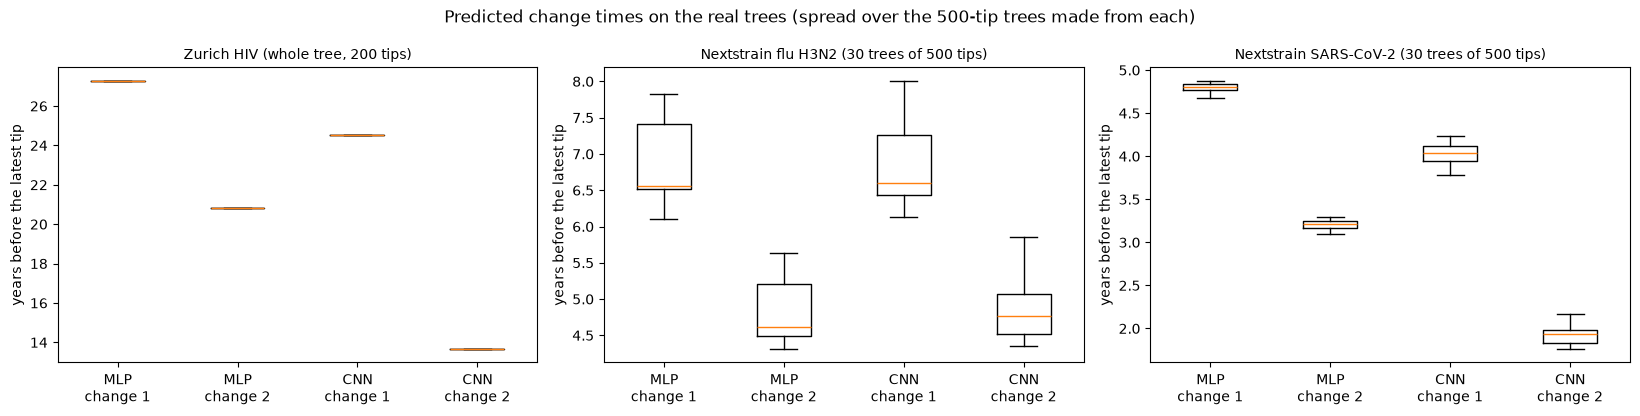

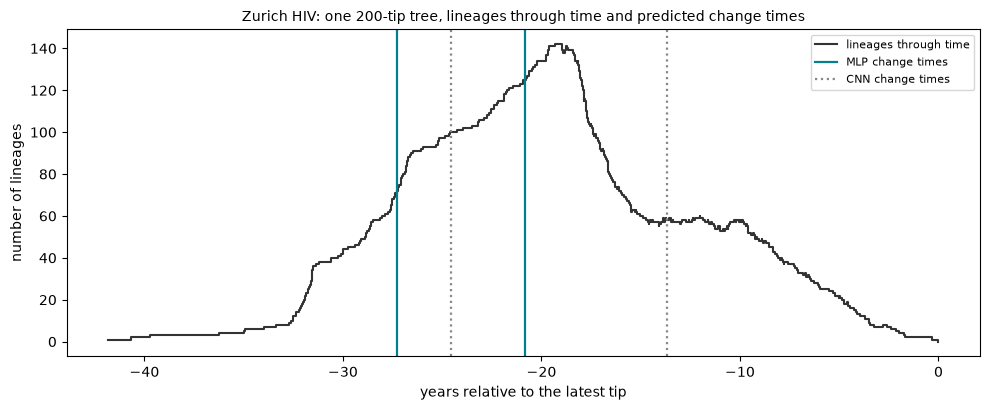

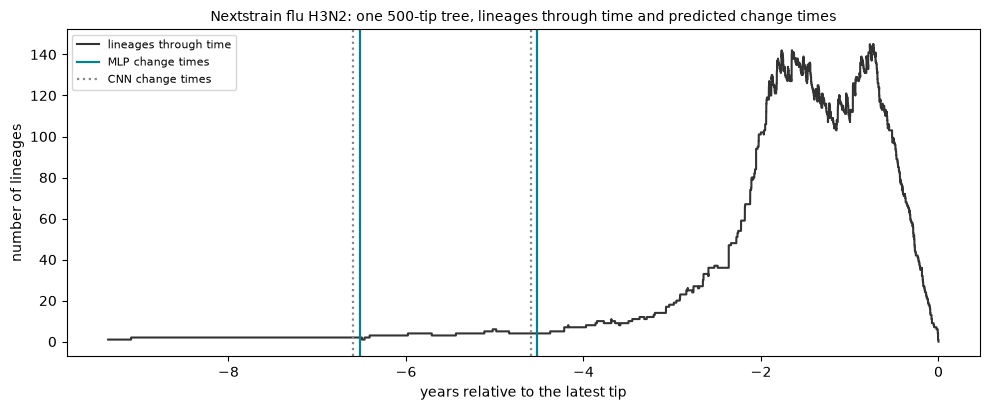

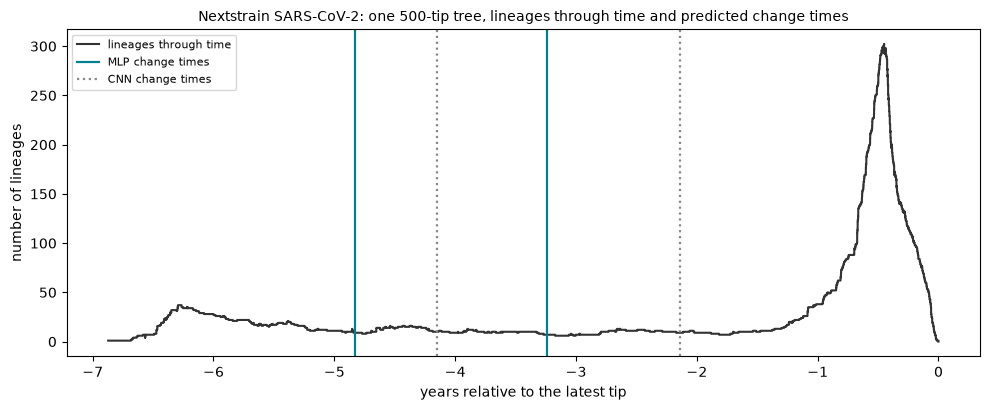

In [17]:
# change times of every real tree: one box per model, MLP first
names = [n for n in REAL[RANGE_TAGS[0]]]
if names:
    fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 4.2), squeeze=False)
    for k, name in enumerate(names):
        ax = axes[0][k]
        data, labels = [], []
        for model_name in MODELS:
            conv = REAL_TABLES[(model_name, name)][1]
            for c in (1, 2):
                data.append(conv["change_time_%d (years before latest tip)" % c].values)
                labels.append("%s\nchange %d" % ("MLP" if model_name == "mlp" else "CNN", c))
        ax.boxplot(data, tick_labels=labels, showfliers=True)
        ax.set_ylabel("years before the latest tip")
        ax.set_title(name + (" (whole tree, %d tips)" % REAL[RANGE_TAGS[0]][name]["info"]["tips"]
                             if REAL[RANGE_TAGS[0]][name]["info"]["tips"] < N_TIPS else " (%d trees of %d tips)" % (len(REAL[RANGE_TAGS[0]][name]["subtrees"]), N_TIPS)), fontsize=10)
    fig.suptitle("Predicted change times on the real trees (spread over the 500-tip trees made from each)", fontsize=12)
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "real_change_times.png"), dpi=110); plt.show()


def plot_real_example(tag, name, which=0):
    # the first 500-tip tree of a real tree: event timeline with the MLP and CNN change times
    s = REAL[tag][name]["subtrees"][which]
    e = s["events"]
    times = e[:, 0] * 10.0
    n, step_t, step_n = 1.0, [0.0], [1.0]
    for k in range(len(times)):
        n += e[k, 2] - e[k, 4]
        step_t.append(times[k]); step_n.append(n)
    to_years = lambda t: (t - s["last_time_model"]) / s["scale"]     # 0 = latest tip, negative = before it
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.step([to_years(t) for t in step_t], step_n, where="post", color="#333333", label="lineages through time")
    colors = {"mlp": "#028090", "cnn": "#888888"}
    for model_name in MODELS:
        p = REAL_PRED[(model_name, tag, name)][which]
        for c in (1, 2):
            ax.axvline(to_years(p[TARGET_NAMES.index("change_time_%d" % c)]), color=colors[model_name],
                       linestyle="-" if model_name == "mlp" else ":", linewidth=1.6,
                       label="%s change times" % ("MLP" if model_name == "mlp" else "CNN") if c == 1 else None)
    ax.set_xlabel("years relative to the latest tip"); ax.set_ylabel("number of lineages")
    ax.set_title("%s: one %d-tip tree, lineages through time and predicted change times" % (name, s["tips"]), fontsize=10)
    ax.legend(fontsize=8); fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "real_example_%s.png" % re.sub(r"\W+", "_", name)), dpi=110); plt.show()

for name in names:
    plot_real_example(RANGE_TAGS[0], name)

## 9. Summary

What can and cannot be concluded from the real trees:
- The simulated test set gives the **accuracy** of the models. The real trees have no known answer, so they only show whether the models give **stable and plausible** answers on real data.
- The spread over the 500-tip trees made from one real tree shows how much the answer depends on which tips are kept.
- The time scale had to be chosen (section 5). Rates per year depend on that choice; λ/μ and the order of the two change times do not.
- Zurich has fewer than 500 tips, so it is outside the training range; flu and SARS-CoV-2 have designed (non-random) sampling and no sampled ancestors, which the simulated trees do not have.

In [18]:
lines = []
for tag in RANGE_TAGS:
    for name in REAL[tag]:
        t = REAL_TABLES[(MODELS[0], name)][0]
        c1, c2 = t.loc["change_time_1 (years before latest tip)"], t.loc["change_time_2 (years before latest tip)"]
        lines.append("%s | %s | change times %.1f and %.1f years before the latest tip (median; 95%% range %.1f-%.1f and %.1f-%.1f)" %
                     (MODEL_LABEL[MODELS[0]], name, c1["median"], c2["median"], c1["2.5%"], c1["97.5%"], c2["2.5%"], c2["97.5%"]))
txt = "\n".join(lines)
print(txt)
open(os.path.join(OUT_DIR, "summary.txt"), "w").write(txt)


MLP (attention, main model) | Zurich HIV | change times 27.3 and 20.8 years before the latest tip (median; 95% range 27.3-27.3 and 20.8-20.8)
MLP (attention, main model) | Nextstrain flu H3N2 | change times 6.6 and 4.6 years before the latest tip (median; 95% range 6.2-7.8 and 4.3-5.6)
MLP (attention, main model) | Nextstrain SARS-CoV-2 | change times 4.8 and 3.2 years before the latest tip (median; 95% range 4.7-4.9 and 3.1-3.3)


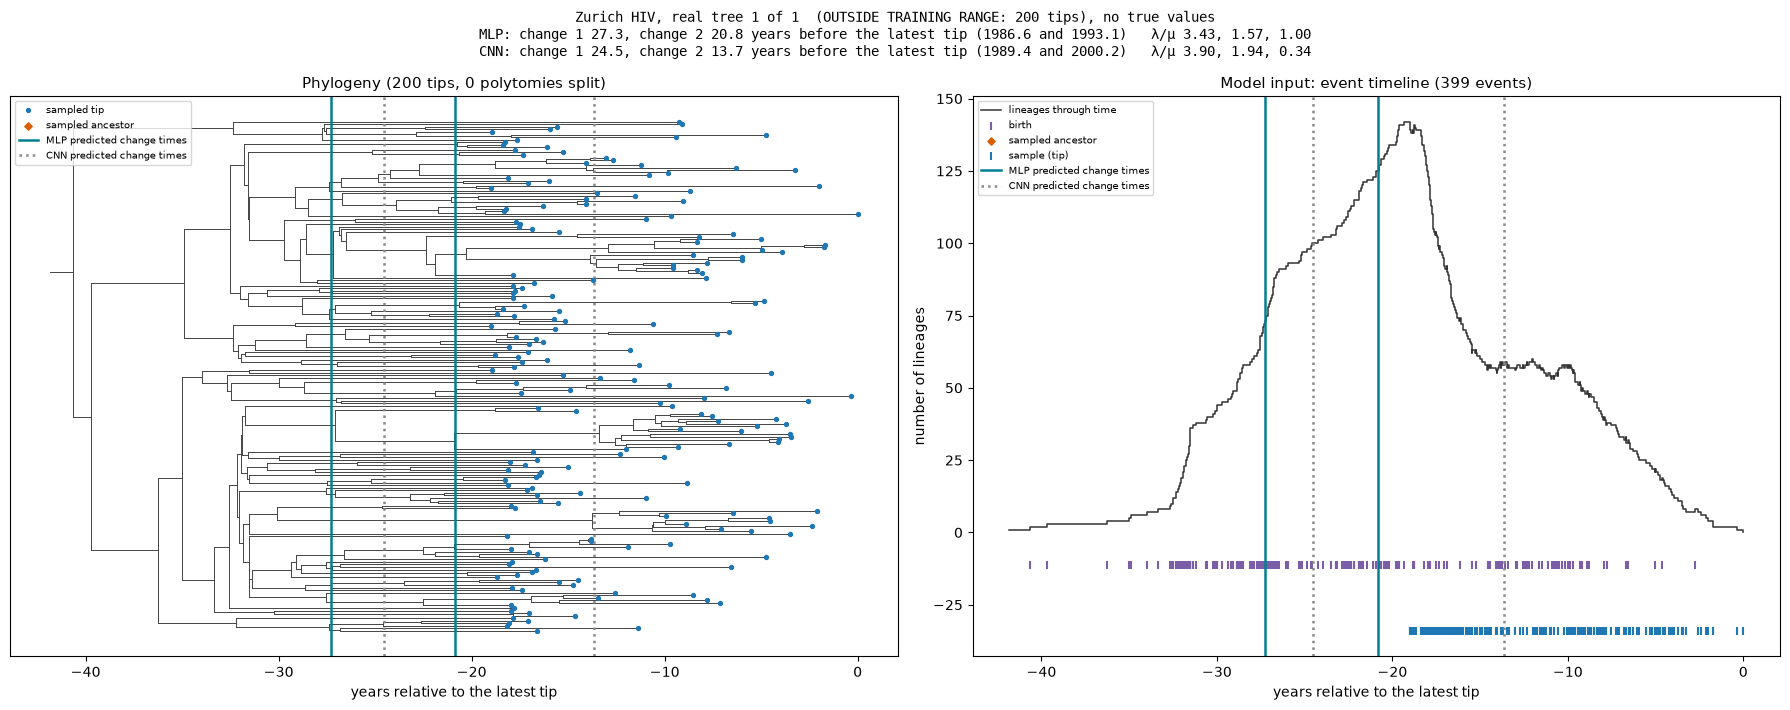

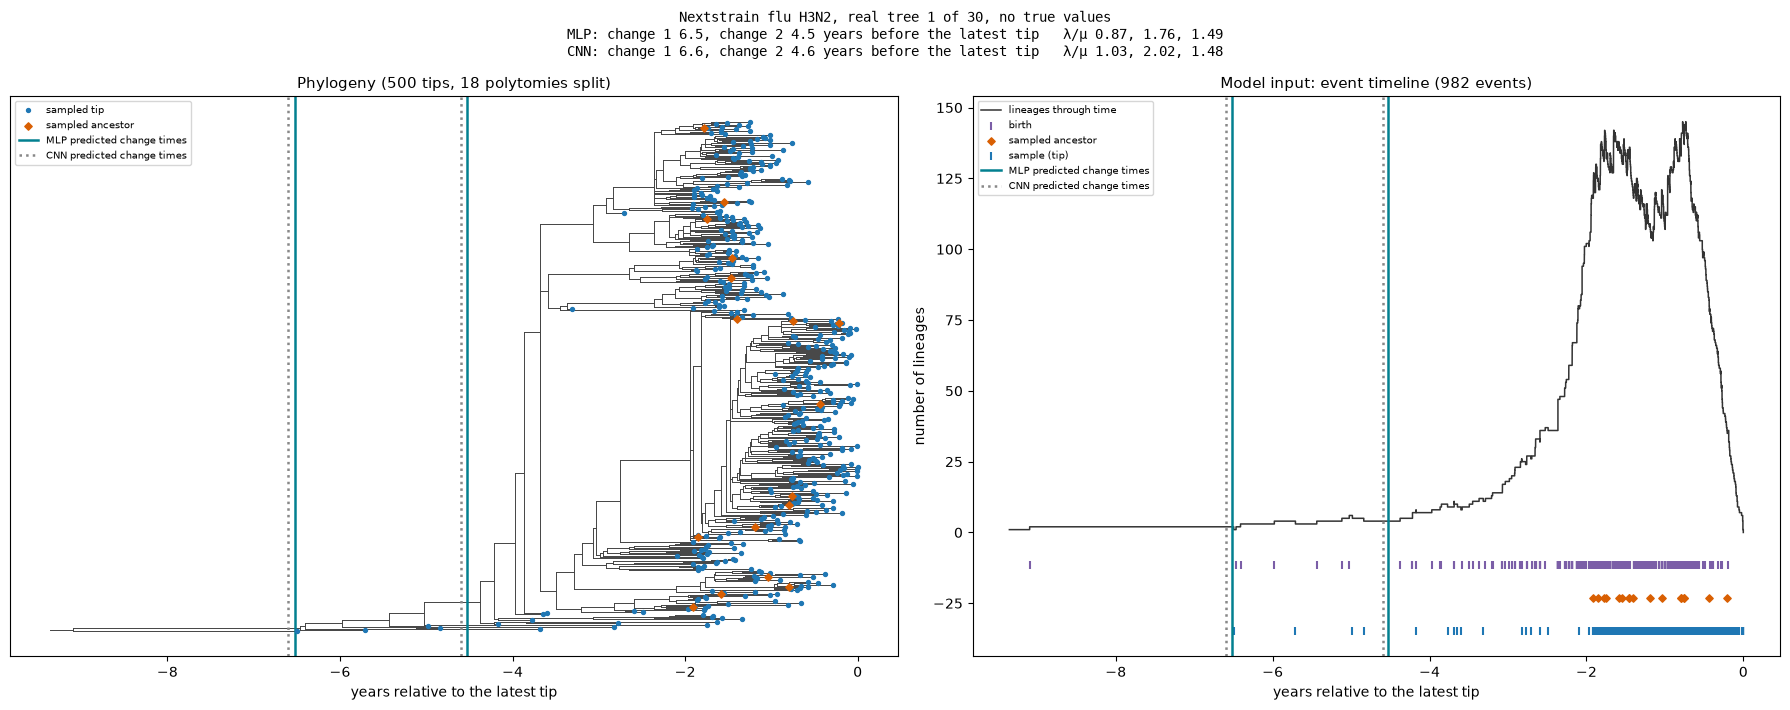

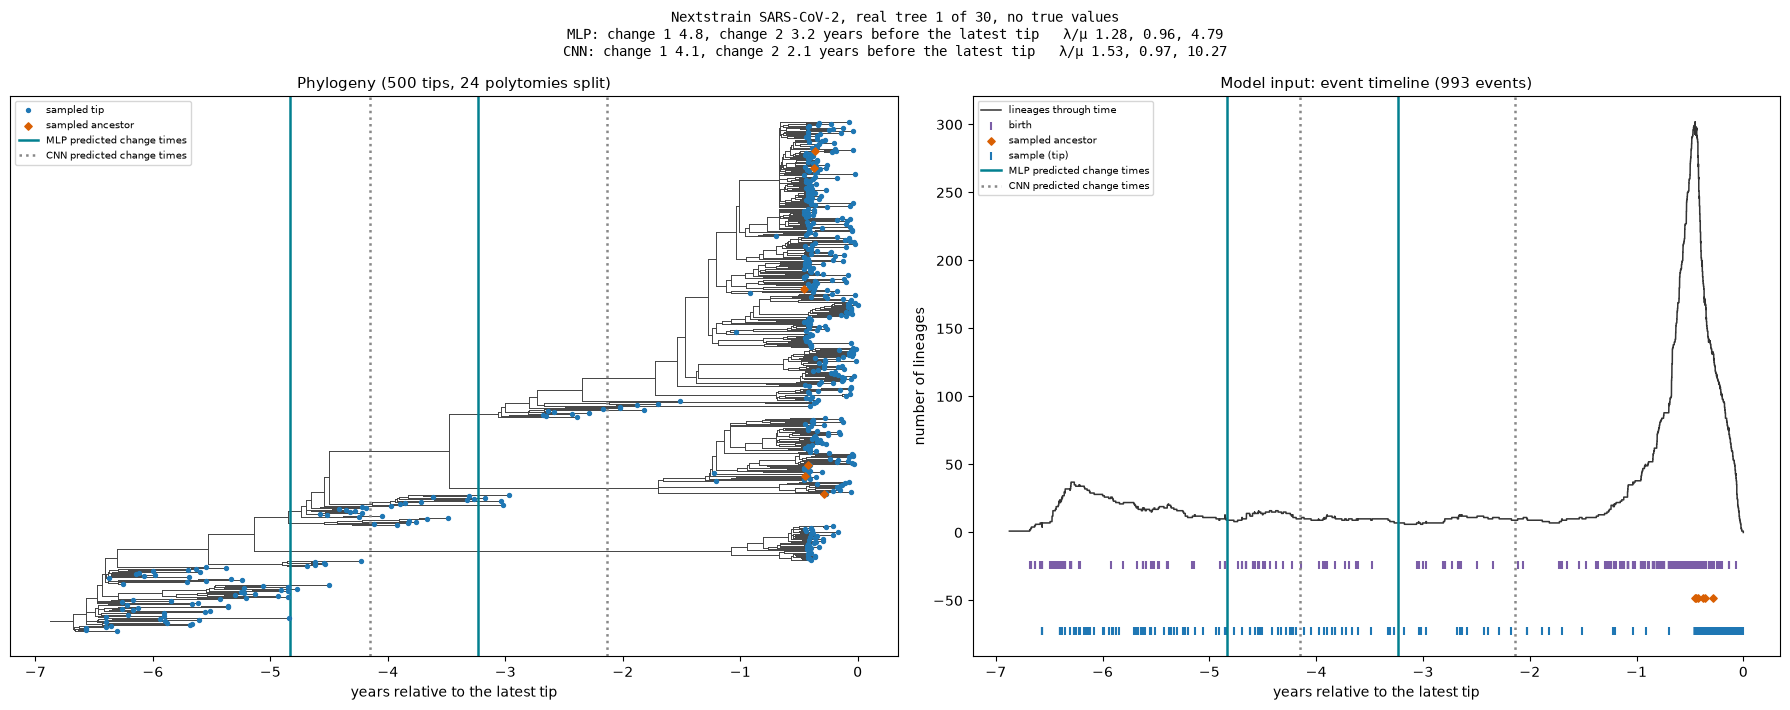

Saved the example trees in /content/drive/MyDrive/capstone_m4/m4_results/example_trees


In [19]:
# ============================================================
# Example trees: one 500-tip tree of each real tree, with the predicted change times
# Run after sections 7 and 8. Uses what is in memory: no training.
# ============================================================
REAL_EXAMPLES = 1                       # how many 500-tip trees to draw for each real tree
EXAMPLE_DIR = os.path.join(OUT_DIR, "example_trees")
os.makedirs(EXAMPLE_DIR, exist_ok=True)
SHORT = {"mlp": "MLP", "cnn": "CNN"}
PRED_STYLE = {"mlp": dict(color="#028090", linestyle="-", linewidth=1.8),
              "cnn": dict(color="#888888", linestyle=":", linewidth=1.8)}


def draw_tree(tree, ax, tmap=lambda t: t):
    # phylogeny on ax: x = time (mapped with tmap), one row per tip; tips blue dots, sampled ancestors orange diamonds
    t_abs = {tree: float(tree.branch_length or 0.0)}
    for node in tree.iter_preorder():
        if node is not tree:
            t_abs[node] = t_abs[node.parent] + float(node.branch_length or 0.0)
    is_sa = lambda n: n.is_leaf() and n is not tree and float(n.branch_length or 0.0) == 0.0
    y_pos, row = {}, 0
    for node in tree.iter_postorder():                      # tips get rows, inner nodes sit between their children
        kids = [c for c in node.children if not is_sa(c)]
        if not kids:
            if not is_sa(node):
                y_pos[node] = row; row += 1
        else:
            y_pos[node] = sum(y_pos[c] for c in kids) / len(kids)
    ax.plot([tmap(0.0), tmap(t_abs[tree])], [y_pos[tree]] * 2, color="#444444", linewidth=0.7)
    tip_x, tip_y, sa_x, sa_y = [], [], [], []
    for node in tree.iter_preorder():
        if is_sa(node):
            sa_x.append(tmap(t_abs[node])); sa_y.append(y_pos[node.parent]); continue
        if node is not tree:
            ax.plot([tmap(t_abs[node.parent]), tmap(t_abs[node])], [y_pos[node]] * 2, color="#444444", linewidth=0.7)
        kids = [c for c in node.children if not is_sa(c)]
        if len(kids) > 1:
            ax.plot([tmap(t_abs[node])] * 2, [min(y_pos[c] for c in kids), max(y_pos[c] for c in kids)], color="#444444", linewidth=0.7)
        if node.is_leaf():
            tip_x.append(tmap(t_abs[node])); tip_y.append(y_pos[node])
    ax.scatter(tip_x, tip_y, s=8, color="#1f77b4", zorder=3, label="sampled tip")
    ax.scatter(sa_x, sa_y, s=14, marker="D", color="#d95f02", zorder=3, label="sampled ancestor")
    ax.set_yticks([])


def draw_timeline(events, ax, tmap=lambda t: t):
    # the model input: lineages through time and the three event types
    real = events[:, 6] > 0
    e = events[real]
    times = e[:, 0] * 10.0
    n, step_t, step_n = 1.0, [0.0], [1.0]
    for k in range(len(times)):
        n += e[k, 2] - e[k, 4]
        step_t.append(times[k]); step_n.append(n)
    ax.step([tmap(t) for t in step_t], step_n, where="post", color="#333333", linewidth=1.1, label="lineages through time")
    top = max(step_n)
    for ch, lab, col, mk, off in [(2, "birth", "#7b5ea7", "|", 0.08), (3, "sampled ancestor", "#d95f02", "D", 0.16),
                                  (4, "sample (tip)", "#1f77b4", "|", 0.24)]:
        m = e[:, ch] > 0.5
        ax.scatter([tmap(t) for t in times[m]], [-off * top] * int(m.sum()), marker=mk, s=14 if mk == "D" else 30, color=col, label=lab)
    ax.set_ylabel("number of lineages")
    return len(times)


def add_change_lines(axes, true_ct, preds, tmap=lambda t: t):
    for ax in axes:
        if true_ct is not None:
            for c in range(2):
                ax.axvline(tmap(true_ct[c]), color="black", linestyle="--", linewidth=1.3, label="true change times" if c == 0 else None)
        for model_name, ct in preds.items():
            for c in range(2):
                ax.axvline(tmap(ct[c]), label="%s predicted change times" % SHORT[model_name] if c == 0 else None, **PRED_STYLE[model_name])
        ax.legend(loc="upper left", fontsize=7)


def plot_real_example_tree(tag, name, which):
    s = REAL[tag][name]["subtrees"][which]
    to_years = lambda t: (t - s["last_time_model"]) / s["scale"]          # 0 = latest tip, negative = years before
    preds = {m: REAL_PRED[(m, tag, name)][which] for m in MODELS}
    tree = load_newick(s["path"])[0]
    fig, axes = plt.subplots(1, 2, figsize=(18, 7.2), gridspec_kw={"width_ratios": [1.1, 1]})
    draw_tree(tree, axes[0], to_years)
    n_events = draw_timeline(s["events"], axes[1], to_years)
    axes[0].set_title("Phylogeny (%d tips, %d polytomies split)" % (s["tips"], s["polytomies"]), fontsize=11)
    axes[1].set_title("Model input: event timeline (%d events)" % n_events, fontsize=11)
    for ax in axes:
        ax.set_xlabel("years relative to the latest tip")
    add_change_lines(axes, None, {m: p[6:8] for m, p in preds.items()}, to_years)
    lines = []
    for m, p in preds.items():
        conv = to_real_units(p, s)
        ct = "change 1 %.1f, change 2 %.1f years before the latest tip" % (conv["change_time_1 (years before latest tip)"],
                                                                            conv["change_time_2 (years before latest tip)"])
        if s["latest_date"] is not None:
            ct += " (%.1f and %.1f)" % (conv["change_time_1 (calendar year)"], conv["change_time_2 (calendar year)"])
        lm = "   λ/μ %.2f, %.2f, %.2f" % tuple(conv["lambda/mu interval %d" % c] for c in (1, 2, 3))
        lines.append("%s: %s%s" % (SHORT[m], ct, lm))
    flag = "  (OUTSIDE TRAINING RANGE: %d tips)" % s["tips"] if s["tips"] < N_TIPS else ""
    fig.suptitle("%s, real tree %d of %d%s, no true values\n%s" %
                 (name, which + 1, len(REAL[tag][name]["subtrees"]), flag, "\n".join(lines)), fontsize=10, family="monospace")
    fig.tight_layout()
    fig.savefig(os.path.join(EXAMPLE_DIR, "real_%s_%d.png" % (re.sub(r"\W+", "_", name), which)), dpi=120)
    plt.show()


for tag in RANGE_TAGS:
    for name in REAL[tag]:
        for which in range(min(REAL_EXAMPLES, len(REAL[tag][name]["subtrees"]))):
            plot_real_example_tree(tag, name, which)
print("Saved the example trees in", EXAMPLE_DIR)

## 10. Checks of the tree processing

These checks test the steps between a tree file and the numbers the models read. They use no training and only take seconds; checks 2 and 3 use the real trees and predictions already in memory.

1. **A small tree worked out by hand.** A 4-tip tree with one sampled ancestor is written down, its event list is worked out by hand and compared with `read_tree_events`. The tip removal (`prune`) and polytomy splitting (`make_binary`) are tested on a second small tree.
2. **The large real trees.** For every 500-tip tree made from a real tree: exactly 500 tips (all 200 for Zurich), every node binary, the tip times unchanged, every group of tips that shares an ancestor in the real tree still sharing one, and the height equal to the median simulated height. The first 500-tip tree of each real tree (the whole tree for Zurich) is also saved with its original tip names for a visual check in iTOL (files in `checks/itol`).
3. **Rescaling and converting back.** The estimates are converted to real units and back, and the rescaled tree heights converted back to years, to check that nothing is lost. The estimates are then turned into reproduction numbers, R_e = λ / (μ + ψ), which do not depend on the time scale, and compared with the range of the simulated trees. Large differences are flagged with **NOTE**.

Every check prints PASS, CHECK (the code does not do what is expected) or NOTE (the code works, but the result needs a comment). The list is saved as `checks/checks_summary.csv`, and the last cell packs all results into `m4_results.zip` for download.


In [20]:
# ============================================================
# Check 1: a small tree worked out by hand
# ============================================================
CHECK_DIR = os.path.join(OUT_DIR, "checks")
ITOL_DIR = os.path.join(CHECK_DIR, "itol")
os.makedirs(ITOL_DIR, exist_ok=True)
CHECK_ROWS = []


def record(check, status, detail=""):
    # status: True = PASS, False = CHECK, or a string such as "NOTE"
    label = status if isinstance(status, str) else ("PASS" if status else "CHECK")
    CHECK_ROWS.append({"check": check, "result": label, "detail": detail})
    print("%-5s  %s%s" % (label, check, ("  |  " + detail) if detail else ""))


def describe(events):
    # event matrix -> readable table (undoes the scaling of the 7 numbers)
    kind = np.where(events[:, 2] > 0.5, "birth", np.where(events[:, 3] > 0.5, "sampled ancestor", "tip"))
    return pd.DataFrame({"time": events[:, 0] * 10, "gap": events[:, 1] / 10, "type": kind,
                         "lineages before": events[:, 5] * 50})


def depths_from_branches(root):
    # time of every tip from the root, added up from the branch lengths (not from the stored times)
    out, stack = {}, [(root, 0.0)]
    while stack:
        node, d = stack.pop()
        if not node.children:
            out[node.name] = d
        for c in node.children:
            stack.append((c, d + c.bl))
    return out


# Stem 1. The root splits at t = 1 into L and R. L splits at t = 2 into tip A (t = 4) and node X (t = 2.5).
# At X a sampled ancestor SA is sampled (zero-length leaf) and the lineage goes on to tip B (t = 3.5).
# R splits at t = 3 into tips C (t = 4.5) and D (t = 6).
SMALL = "((A:2.0,(B:1.0,SA:0.0):0.5):1.0,(C:1.5,D:3.0):2.0):1.0;"
small_path = os.path.join(CHECK_DIR, "small_tree.nwk")
open(small_path, "w").write(SMALL)

# worked out by hand: (time, type, lineages just before the event)
HAND = [(1.0, "birth", 1), (2.0, "birth", 2), (2.5, "sampled ancestor", 3), (3.0, "birth", 3),
        (3.5, "tip", 4), (4.0, "tip", 3), (4.5, "tip", 2), (6.0, "tip", 1)]
hand = pd.DataFrame(HAND, columns=["time", "type", "lineages before"])
hand.insert(1, "gap", np.diff(np.concatenate([[0.0], hand["time"].values])))

events, last_time, stem = read_tree_events(small_path)
code = describe(events)
print("Small tree:", SMALL)
print(pd.concat({"by hand": hand, "read_tree_events": code}, axis=1).round(3).to_string())
same = (len(code) == len(hand) and np.allclose(code["time"], hand["time"]) and np.allclose(code["gap"], hand["gap"])
        and (code["type"].values == hand["type"].values).all() and np.allclose(code["lineages before"], hand["lineages before"]))
print()
record("1a event list of the small tree equals the hand-worked list", same, "%d events" % len(code))
record("1b stem and time of the last sample", np.isclose(stem, 1.0) and np.isclose(last_time, 6.0),
       "stem %.1f (hand 1.0), last sample %.1f (hand 6.0)" % (stem, last_time))
record("1c padding flag and scaling (time/10, gap*10, lineages/50)",
       np.allclose(events[:, 6], 1) and np.isclose(events[0, 0], 0.1) and np.isclose(events[0, 1], 10) and np.isclose(events[0, 5], 0.02))

# prune and make_binary on a tree with a polytomy: ((A,B,C),(D,E))
POLY = "((A:1.0,B:1.0,C:1.0):1.0,(D:2.0,E:1.0):1.0):0.0;"
poly_path = os.path.join(CHECK_DIR, "small_polytomy.nwk")
open(poly_path, "w").write(POLY)
full_small = load_real_tree(poly_path)
before = depths_from_branches(full_small)

# keep A, B, D: by hand the result is ((A:1,B:1):1,D:3) - C and E removed, D's parent merged into D's branch
keep = {id(n) for n in leaves_of(full_small) if n.name in ("A", "B", "D")}
pruned = prune(full_small, keep)
after = depths_from_branches(pruned)
inner = [n for n in postorder(pruned) if n.children]
record("1d prune keeps the chosen tips at their times", sorted(after) == ["A", "B", "D"] and all(np.isclose(after[k], before[k]) for k in after),
       "A %.1f, B %.1f, D %.1f (hand 2, 2, 3)" % (after["A"], after["B"], after["D"]))
record("1e prune merges nodes left with one child", len(inner) == 2 and all(len(n.children) == 2 for n in inner),
       "%d inner nodes (hand 2)" % len(inner))

binary_small = load_real_tree(poly_path)
n_split = make_binary(binary_small, random.Random(0))
after_b = depths_from_branches(binary_small)
inner_b = [n for n in postorder(binary_small) if n.children]
record("1f make_binary splits the polytomy without moving tips",
       n_split == 1 and len(inner_b) == 4 and all(len(n.children) == 2 for n in inner_b) and all(np.isclose(after_b[k], before[k]) for k in before),
       "%d polytomy split, %d inner nodes (hand 1 and 4)" % (n_split, len(inner_b)))


Small tree: ((A:2.0,(B:1.0,SA:0.0):0.5):1.0,(C:1.5,D:3.0):2.0):1.0;
  by hand                                        read_tree_events                                       
     time  gap              type lineages before             time  gap              type lineages before
0     1.0  1.0             birth               1              1.0  1.0             birth             1.0
1     2.0  1.0             birth               2              2.0  1.0             birth             2.0
2     2.5  0.5  sampled ancestor               3              2.5  0.5  sampled ancestor             3.0
3     3.0  0.5             birth               3              3.0  0.5             birth             3.0
4     3.5  0.5               tip               4              3.5  0.5               tip             4.0
5     4.0  0.5               tip               3              4.0  0.5               tip             3.0
6     4.5  0.5               tip               2              4.5  0.5               tip    

In [21]:
# ============================================================
# Check 2: the large real trees
# ============================================================
def newick_named(root, scale=1.0):
    # like to_newick, but keeps the original tip names (quoted when needed) and no stem; for iTOL
    def name(n):
        s = n.name or ""
        return "'" + s.replace("'", "''") + "'" if re.search(r"[\s():,;\[\]']", s) else s
    def rec(n):
        if not n.children:
            return "%s:%.10f" % (name(n), n.bl * scale)
        return "(" + ",".join(rec(c) for c in n.children) + "):%.10f" % (n.bl * scale)
    return "(" + ",".join(rec(c) for c in root.children) + ");"


def clades(root, keep_ids=None):
    # every group of tips below one node (only tips in keep_ids, if given), as frozensets of tip ids
    below, out = {}, set()
    for n in postorder(root):
        if not n.children:
            below[id(n)] = frozenset([id(n)]) if keep_ids is None or id(n) in keep_ids else frozenset()
        else:
            below[id(n)] = frozenset().union(*(below[id(c)] for c in n.children))
            if len(below[id(n)]) >= 2:
                out.add(below[id(n)])
    return out


def rebuild_first_subtree(name, cfg, tag):
    # repeats make_subtrees for the first 500-tip tree, keeping the original nodes so tips can be matched
    full = load_real_tree(os.path.join(DATA_DIR, cfg["file"]))
    full_leaves = leaves_of(full)
    rng = random.Random(REAL_SEED)
    if len(full_leaves) < N_TIPS:
        groups = [full_leaves]
    elif cfg["mode"] == "random":
        groups = [rng.sample(full_leaves, N_TIPS) for _ in range(N_SUBTREES)]
    else:
        return None
    keep_ids = {id(n) for n in groups[0]}
    pruned = prune(full, keep_ids)
    restricted = clades(full, keep_ids)
    make_binary(pruned, rng)
    return full, pruned, groups[0], restricted


for tag in RANGE_TAGS:
    st = TRAIN_STATS[tag]
    for name, r in REAL[tag].items():
        cfg, subs = REAL_TREES[name], r["subtrees"]
        n_tips = subs[0]["tips"]
        short = re.sub(r"\W+", "_", name)
        print("-" * 90); print(name); print("-" * 90)

        # (a) every 500-tip tree: number of tips, binary, height on the model scale, event counts
        bad_tips, bad_binary, height_err, back_err, zero_tips = 0, 0, 0.0, 0.0, []
        for s in subs:
            tree = load_newick(s["path"])[0]
            leaves = [n for n in tree.iter_preorder() if n.is_leaf()]
            inner = [n for n in tree.iter_preorder() if not n.is_leaf()]
            bad_tips += len(leaves) != n_tips
            bad_binary += any(len(n.children) != 2 for n in inner)
            height_err = max(height_err, abs((s["last_time_model"] - s["stem"]) - st["height_median"]))
            back_err = max(back_err, abs((s["last_time_model"] - s["stem"]) / s["scale"] - s["height_years"]))
            zero_tips.append(int(s["events"][:, 3].sum()))
        record("2a %s: every tree has %d tips" % (name, n_tips), bad_tips == 0, "%d of %d trees wrong" % (bad_tips, len(subs)))
        record("2b %s: every node is binary" % name, bad_binary == 0, "%d of %d trees with a non-binary node" % (bad_binary, len(subs)))
        record("2c %s: height equals the simulated median %.3f" % (name, st["height_median"]), height_err < 1e-5,
               "largest difference %.2e model units" % height_err)
        record("2d %s: rescaled height converted back to years" % name, back_err < 1e-5,
               "largest difference %.2e years (tree height about %.1f years)" % (back_err, np.median([s["height_years"] for s in subs])))
        if np.median(zero_tips) > 0:
            record("2e %s: tips on a zero-length branch are read as sampled ancestors" % name, "NOTE",
                   "median %d per tree; the real tree has tips sampled at the same time as their parent node, which "
                   "read_tree_events treats like the sampled ancestors of the simulations" % np.median(zero_tips))

        # (b) the first 500-tip tree, rebuilt with the original tips
        rebuilt = rebuild_first_subtree(name, cfg, tag)
        if rebuilt is None:
            print("  mode '%s': rebuild skipped" % cfg["mode"]); continue
        full, pruned, group, restricted = rebuilt
        s0 = subs[0]
        same_file = to_newick(pruned, s0["scale"], s0["stem"]) == open(s0["path"]).read()
        record("2f %s: rebuilt first tree is identical to the file the models read" % name, same_file)

        root_t = pruned.t
        new_depth = depths_from_branches(pruned)
        old_depth = {}
        for n in group:
            old_depth.setdefault(n.name, []).append(n.t - root_t)
        diffs = [min(abs(new_depth[k] - d) for d in old_depth[k]) for k in new_depth]
        record("2g %s: tip times unchanged by pruning and polytomy splitting" % name, max(diffs) < 1e-6,
               "largest difference %.2e years over %d tips" % (max(diffs), len(diffs)))

        # groups of tips that share an ancestor in the real tree must still share one (splitting polytomies only adds groups)
        id_by_name = {}
        for n in group:
            id_by_name.setdefault(n.name, id(n))
        unique_names = len(id_by_name) == len(group)
        if unique_names:
            pruned_groups = {frozenset(id_by_name[l.name] for l in leaves_of(c)) for c in postorder(pruned) if c.children}
            missing = len(restricted - pruned_groups)
            record("2h %s: every group of tips with a common ancestor is kept" % name, missing == 0,
                   "%d groups in the real tree, %d missing; %d added by splitting polytomies" %
                   (len(restricted), missing, len(pruned_groups - restricted)))
        else:
            record("2h %s: groups of tips" % name, "NOTE", "tip names are not unique, check skipped")

        # files for iTOL: the original tree, and the first 500-tip tree in years with its original tip names
        orig_out = os.path.join(ITOL_DIR, "%s_original.nwk" % short)
        sub_out = os.path.join(ITOL_DIR, "%s_subtree1_years.nwk" % short)
        open(orig_out, "w").write(open(os.path.join(DATA_DIR, cfg["file"])).read())
        open(sub_out, "w").write(newick_named(pruned))
        pd.Series(sorted(new_depth)).to_csv(os.path.join(ITOL_DIR, "%s_kept_tip_names.txt" % short), index=False, header=False)
        print("  for iTOL: %s, %s and the list of kept tips" % (os.path.basename(orig_out), os.path.basename(sub_out)))


------------------------------------------------------------------------------------------
Zurich HIV
------------------------------------------------------------------------------------------
PASS   2a Zurich HIV: every tree has 200 tips  |  0 of 1 trees wrong
PASS   2b Zurich HIV: every node is binary  |  0 of 1 trees with a non-binary node
PASS   2c Zurich HIV: height equals the simulated median 9.015  |  largest difference 1.16e-10 model units
PASS   2d Zurich HIV: rescaled height converted back to years  |  largest difference 5.21e-10 years (tree height about 40.7 years)
PASS   2f Zurich HIV: rebuilt first tree is identical to the file the models read
PASS   2g Zurich HIV: tip times unchanged by pruning and polytomy splitting  |  largest difference 0.00e+00 years over 200 tips
PASS   2h Zurich HIV: every group of tips with a common ancestor is kept  |  199 groups in the real tree, 0 missing; 0 added by splitting polytomies
  for iTOL: Zurich_HIV_original.nwk, Zurich_HIV_subtree1_y

In [22]:
# ============================================================
# Check 3: converting back to real units, and reproduction numbers
# ============================================================
# (a) estimates -> real units -> model units again
for tag in RANGE_TAGS:
    for name in REAL[tag]:
        worst = 0.0
        for model_name in MODELS:
            for p, s in zip(REAL_PRED[(model_name, tag, name)], REAL[tag][name]["subtrees"]):
                conv = to_real_units(p, s)
                back = []
                for j, t in enumerate(TARGET_NAMES):
                    if t.startswith("change_time"):
                        back.append(s["last_time_model"] - conv[t + " (years before latest tip)"] * s["scale"])
                    else:
                        back.append(conv[t + " (per year)"] / s["scale"])
                worst = max(worst, np.max(np.abs(np.array(back) - p) / np.abs(p)))
        record("3a %s: estimates converted to years and back" % name, worst < 1e-6, "largest relative difference %.2e" % worst)

# (b) reproduction numbers R_e = lambda / (mu + psi). psi = 1 in model units, i.e. psi = scale per year,
#     so R_e is the same in both units. Compared with the simulated training trees.
RE_ROWS = []
for tag in RANGE_TAGS:
    X, y, trees_set = prepare_dataset(tag)
    y_train = y[SPLITS[tag][0]]
    for k in (1, 2, 3):
        lam, mu = TARGET_NAMES.index("lambda_%d" % k), TARGET_NAMES.index("mu_%d" % k)
        sim_re = y_train[:, lam] / (y_train[:, mu] + 1.0)
        lo, hi, top = np.quantile(sim_re, 0.025), np.quantile(sim_re, 0.975), sim_re.max()
        for name in REAL[tag]:
            subs = REAL[tag][name]["subtrees"]
            for model_name in MODELS:
                P = REAL_PRED[(model_name, tag, name)]
                re_model = P[:, lam] / (P[:, mu] + 1.0)
                re_years = np.array([to_real_units(p, s)["lambda_%d (per year)" % k] /
                                     (to_real_units(p, s)["mu_%d (per year)" % k] + s["scale"]) for p, s in zip(P, subs)])
                RE_ROWS.append({"tree": name, "model": SHORT[model_name], "interval": k,
                                "R_e median": np.median(re_model), "R_e 2.5%": np.quantile(re_model, 0.025),
                                "R_e 97.5%": np.quantile(re_model, 0.975),
                                "simulated 2.5%": lo, "simulated 97.5%": hi, "simulated max": top,
                                "same in years": bool(np.allclose(re_model, re_years, rtol=1e-6))})

RE_TABLE = pd.DataFrame(RE_ROWS)
RE_TABLE.round(3).to_csv(os.path.join(CHECK_DIR, "reproduction_numbers.csv"), index=False)
print()
print(RE_TABLE.drop(columns="same in years").round(2).to_string(index=False))
print()
record("3b R_e is the same in model units and per year", RE_TABLE["same in years"].all())

# a large difference: the median lies outside the middle 95% of the simulated trees, or within 2% of the largest simulated value
for name in REAL[RANGE_TAGS[0]]:
    rows = RE_TABLE[(RE_TABLE["tree"] == name) & (RE_TABLE["model"] == "MLP")]
    flagged = [r for _, r in rows.iterrows()
               if r["R_e median"] < r["simulated 2.5%"] or r["R_e median"] > r["simulated 97.5%"] or r["R_e median"] > 0.98 * r["simulated max"]]
    detail = ", ".join("interval %d: %.2f (simulated 95%% %.2f-%.2f, max %.2f)" %
                       (r["interval"], r["R_e median"], r["simulated 2.5%"], r["simulated 97.5%"], r["simulated max"]) for r in flagged)
    record("3c %s: MLP R_e inside the simulated range" % name, "NOTE" if flagged else True,
           detail if flagged else "all three intervals inside")

# optional: published R_e values, e.g. {("Zurich HIV", 1): 1.5}; differences larger than 50% are flagged
PUBLISHED_RE = {}
for (name, k), value in PUBLISHED_RE.items():
    r = RE_TABLE[(RE_TABLE["tree"] == name) & (RE_TABLE["model"] == "MLP") & (RE_TABLE["interval"] == k)]
    if len(r):
        est = float(r["R_e median"].iloc[0])
        record("3d %s interval %d: R_e %.2f against published %.2f" % (name, k, est, value), "NOTE" if abs(est / value - 1) > 0.5 else True)


PASS   3a Zurich HIV: estimates converted to years and back  |  largest relative difference 8.72e-08
PASS   3a Nextstrain flu H3N2: estimates converted to years and back  |  largest relative difference 1.16e-07
PASS   3a Nextstrain SARS-CoV-2: estimates converted to years and back  |  largest relative difference 2.54e-07

                 tree model  interval  R_e median  R_e 2.5%  R_e 97.5%  simulated 2.5%  simulated 97.5%  simulated max
           Zurich HIV   MLP         1        0.76      0.76       0.76            0.09             0.84           0.91
           Zurich HIV   CNN         1        0.71      0.71       0.71            0.09             0.84           0.91
  Nextstrain flu H3N2   MLP         1        0.45      0.37       0.53            0.09             0.84           0.91
  Nextstrain flu H3N2   CNN         1        0.47      0.38       0.51            0.09             0.84           0.91
Nextstrain SARS-CoV-2   MLP         1        0.51      0.49       0.54           

In [23]:
# ============================================================
# Summary of the checks, and all results packed for download
# ============================================================
summary = pd.DataFrame(CHECK_ROWS)
summary.to_csv(os.path.join(CHECK_DIR, "checks_summary.csv"), index=False)
print(summary["result"].value_counts().to_string())
print("\nSaved", os.path.join(CHECK_DIR, "checks_summary.csv"))

import shutil
shutil.make_archive("/content/m4_results", "zip", OUT_DIR)
shutil.make_archive("/content/m4_models", "zip", MODEL_DIR)
print("Saved /content/m4_results.zip (tables, plots, predictions, real 500-tip trees, checks and iTOL files)")
print("Saved /content/m4_models.zip (trained weights: upload and unzip into /content/m4_models to skip training next time)")

result
PASS    34
NOTE     2

Saved /content/drive/MyDrive/capstone_m4/m4_results/checks/checks_summary.csv
Saved /content/m4_results.zip (tables, plots, predictions, real 500-tip trees, checks and iTOL files)
Saved /content/m4_models.zip (trained weights: upload and unzip into /content/m4_models to skip training next time)
